# Pyramid (coarse-to-fine) Grover template matching

Notebook 01 searched every window of a tiny 8×8 image. Here the scene is harder: a **64×64 grayscale** image with a smooth random background, strong Gaussian noise, a Waldo pasted with a *different brightness and contrast*, and three look-alike decoys. The full-resolution search needs **2401 windows** and **20 qubits** (8 data + 12 index).

**Why a pyramid helps.** Pooling the image 2×2 shrinks *both* the number of windows (index register) and the template length (data register). Averaging also cuts the pixel noise. So:

1. search *all* windows at the coarsest level (cheap),
2. keep the top-k candidate positions,
3. at the next finer level, search only a small neighbourhood (±`radius` pixels) around each candidate,
4. repeat until full resolution.

Each level is one Grover run of the same algorithm as before; only the *database* changes.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from grover_tm import (SceneGenerator, WindowExtractor, WindowDatabase, NEQREncoder, AmplitudeNCCEncoder,
                       GroverTemplateMatcher, AnalyticEngine, CircuitEngine,
                       ImagePyramid, PyramidMatcher, TexturedSceneGenerator,
                       MatchVisualizer, PyramidVisualizer)
np.set_printoptions(precision=3, suppress=True)

## 1. Two engines, one interface
Simulating the real circuits is only feasible up to ~12 qubits with exact state loading. For the big levels we use `AnalyticEngine`, which applies the paper's closed form (Eq. 17), `P_k(t) = P_k(0)·(sin((2t+1)θ)/sinθ)²`. Before trusting it, we check it against the real circuits (`GroverTemplateMatcher`) on the small scene from notebook 01.

In [2]:
small = SceneGenerator().make()
db_s = WindowDatabase(small.image, WindowExtractor((4, 4)), NEQREncoder((4, 4)))
m_s = GroverTemplateMatcher(db_s, small.waldo)
analytic = AnalyticEngine()

for t in range(5):
    assert np.allclose(analytic.joint_probabilities(db_s, small.waldo, t), m_s.exact_joint(t))
print("analytic formula == circuit simulation for t = 0..4")

rep_c = CircuitEngine().search(db_s, small.waldo, shots=8192, seed=1)
rep_a = analytic.search(db_s, small.waldo, shots=8192, seed=1)
w = db_s.positions.index(small.waldo_position)
print("circuit engine : t =", rep_c.num_iterations, "best =", db_s.position_of(rep_c.result.best_index))
print("analytic engine: t =", rep_a.num_iterations, "best =", db_s.position_of(rep_a.result.best_index))
assert rep_c.num_iterations == rep_a.num_iterations and rep_c.result.best_index == rep_a.result.best_index == w

analytic formula == circuit simulation for t = 0..4


circuit engine : t = 1 best = (4, 3)
analytic engine: t = 1 best = (4, 3)


## 2. The hard scene
Green dashed = true Waldo. Decoys: a *mirrored* Waldo, a copy with *half of its blocks replaced*, and a copy with *35 % corrupted pixels*. Waldo sits at an odd offset (37, 23), so it is not aligned with the 2×2 pooling grid.

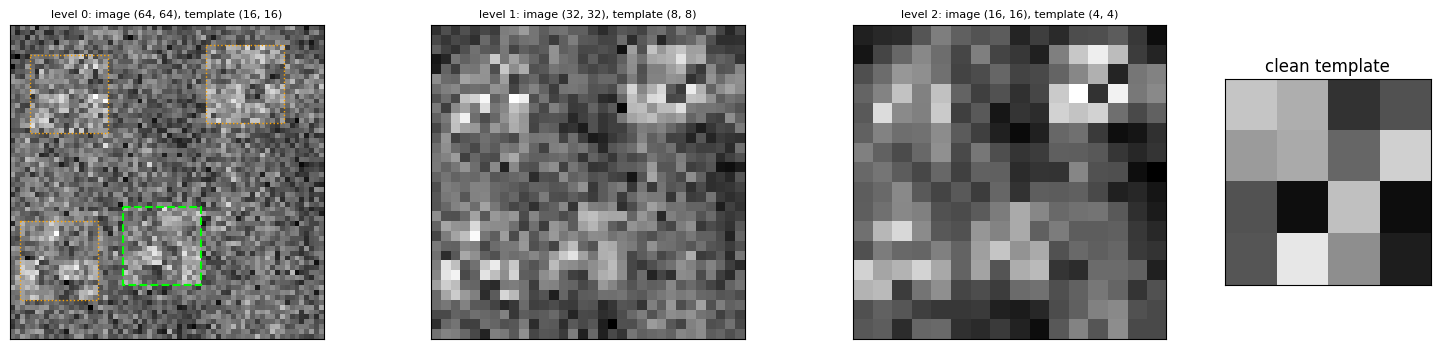

In [3]:
scene = TexturedSceneGenerator(scene_shape=(64, 64), template_size=16, noise_std=0.30, seed=3).make()
pyr = ImagePyramid(scene.image, scene.waldo, num_levels=3)
H = 16

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, .5]})
PyramidVisualizer.show_pyramid(pyr, ax[:3])
r, c = scene.waldo_position
ax[0].add_patch(plt.Rectangle((c - .5, r - .5), H, H, fill=False, ec="lime", lw=1.5, ls="--"))
for name, (dr, dc) in scene.decoys:
    ax[0].add_patch(plt.Rectangle((dc - .5, dr - .5), H, H, fill=False, ec="orange", lw=1, ls=":"))
MatchVisualizer.show_template(scene.waldo, ax[3], "clean template")
plt.tight_layout(); plt.show()

## 3. Baseline: one flat search at full resolution (1 level)

In [4]:
engine = AnalyticEngine()
flat = PyramidMatcher(engine, shots=4096).run(ImagePyramid(scene.image, scene.waldo, 1), seed=1)
L = flat.levels[0]
print(f"flat    : found {flat.position} (true {scene.waldo_position}) | windows {L.db.n_windows} | "
      f"qubits {L.n_qubits} (n_D={L.db.n_data_qubits}, n_I={L.db.n_index_qubits}) | t = {L.report.num_iterations}")

flat    : found (37, 23) (true (37, 23)) | windows 2401 | qubits 20 (n_D=8, n_I=12) | t = 6


## 4. Pyramid search (3 levels, top-3 candidates, ±2 px refinement)

In [5]:
pm = PyramidMatcher(engine, top_k=3, radius=2, shots=4096)
res = pm.run(pyr, seed=1)

print(f"pyramid : found {res.position} (true {scene.waldo_position})\n")
print(f"{'level':>5} {'image':>9} {'tmpl':>6} {'windows':>8} {'n_D':>4} {'n_I':>4} {'qubits':>6} {'t':>3}  top candidates (position, prob)")
for lr in res.levels:
    print(f"{lr.level:>5} {str(pyr.images[lr.level].shape):>9} {str(pyr.templates[lr.level].shape):>6} {lr.db.n_windows:>8} "
          f"{lr.db.n_data_qubits:>4} {lr.db.n_index_qubits:>4} {lr.n_qubits:>6} {lr.report.num_iterations:>3}  "
          + ", ".join(f"{p}:{q:.2f}" for p, q in lr.candidates))
assert res.position == scene.waldo_position

pyramid : found (37, 23) (true (37, 23))

level     image   tmpl  windows  n_D  n_I qubits   t  top candidates (position, prob)
    2  (16, 16) (4, 4)      169    4    8     12   3  (9, 6):0.06, (1, 1):0.04, (1, 10):0.03
    1  (32, 32) (8, 8)       75    6    7     13   3  (3, 2):0.12, (18, 11):0.12, (19, 11):0.08
    0  (64, 64) (16, 16)       60    8    6     14   3  (37, 23):0.14


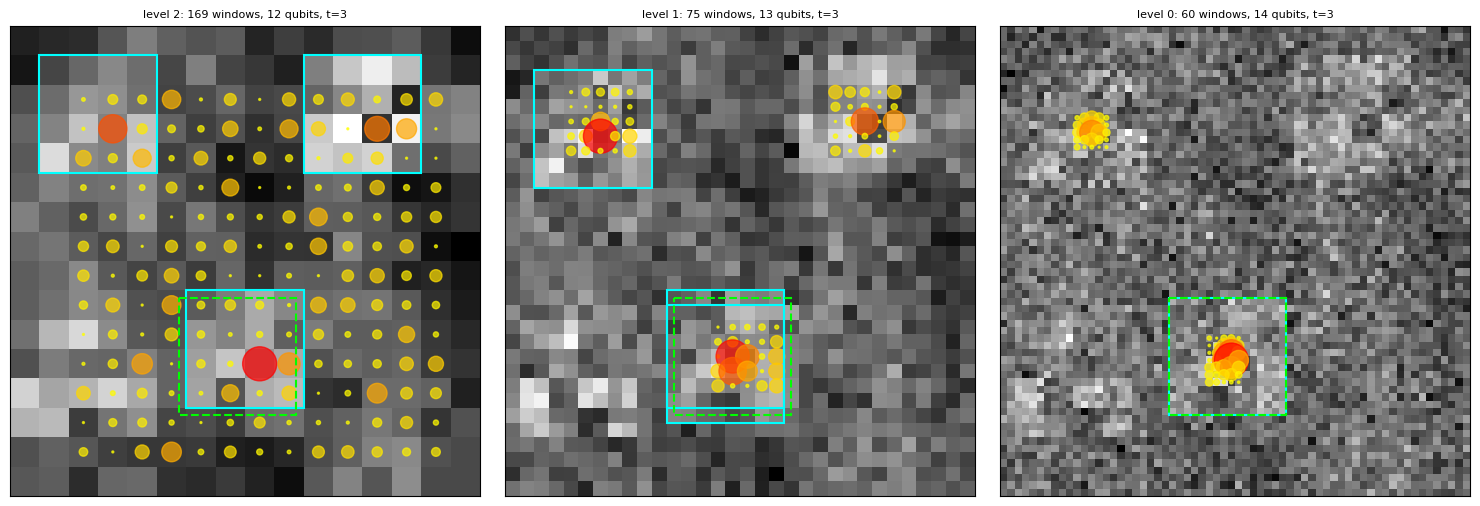

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, lr in zip(ax, res.levels):                        # coarse -> fine
    l = lr.level
    PyramidVisualizer.show_level(lr, pyr.images[l], pyr.templates[l].shape,
                                 true_pos=(scene.waldo_position[0] / 2**l, scene.waldo_position[1] / 2**l), ax=a)
plt.tight_layout(); plt.show()

Dots = searched windows (size/colour ∝ measured probability), cyan boxes = candidates passed on, green dashed = truth. Note how the finer levels only look at small patches around the coarse candidates.

## 5. What did the pyramid save?

In [7]:
rows = [("flat (1 level)", flat), ("pyramid (3 levels)", res)]
print(f"{'method':<20} {'max qubits':>10} {'windows searched':>17} {'sum of t':>9} {'~load cost (2^qubits)':>22}  {'correct':>7}")
for name, r_ in rows:
    print(f"{name:<20} {r_.max_qubits:>10} {r_.total_windows:>17} {r_.total_iterations:>9} {2**r_.max_qubits:>22,}  {str(r_.position == scene.waldo_position):>7}")

method               max qubits  windows searched  sum of t  ~load cost (2^qubits)  correct
flat (1 level)               20              2401         6              1,048,576     True
pyramid (3 levels)           14               304         9                 16,384     True


*Load cost* is only the scaling of exact state loading (~2^qubits CNOTs); the pyramid's biggest register is 6 qubits smaller (20 → 14), i.e. ~64× cheaper to load. The number of Grover iterations is not the saving here: the amplification is cheap in both cases, the savings are in **window count and register sizes**.

## 6. Robustness sweep: noise level vs success
12 random scenes per noise level, success = *exact* pixel position found.

noise std 0.15:  flat 12/12   pyramid 12/12


noise std 0.30:  flat  9/12   pyramid 12/12


noise std 0.45:  flat  9/12   pyramid  9/12


noise std 0.60:  flat  2/12   pyramid  4/12


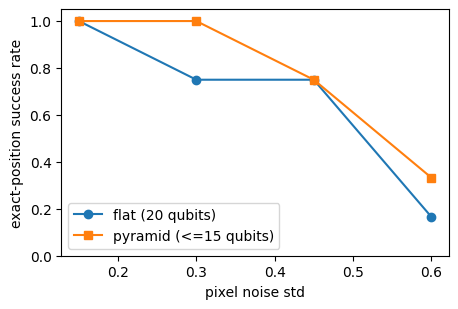

In [8]:
noise_levels = [0.15, 0.30, 0.45, 0.60]
n_scenes = 12
stats = {"flat": [], "pyramid": []}
for nz in noise_levels:
    ok = {"flat": 0, "pyramid": 0}
    for s in range(n_scenes):
        sc = TexturedSceneGenerator(seed=s, noise_std=nz).make()
        ok["flat"]    += PyramidMatcher(engine).run(ImagePyramid(sc.image, sc.waldo, 1), seed=s).position == sc.waldo_position
        ok["pyramid"] += PyramidMatcher(engine).run(ImagePyramid(sc.image, sc.waldo, 3), seed=s).position == sc.waldo_position
    for k in ok: stats[k].append(ok[k] / n_scenes)
    print(f"noise std {nz:.2f}:  flat {ok['flat']:>2}/{n_scenes}   pyramid {ok['pyramid']:>2}/{n_scenes}")

plt.figure(figsize=(5, 3.2))
plt.plot(noise_levels, stats["flat"], "o-", label="flat (20 qubits)")
plt.plot(noise_levels, stats["pyramid"], "s-", label="pyramid (<=15 qubits)")
plt.xlabel("pixel noise std"); plt.ylabel("exact-position success rate"); plt.ylim(0, 1.05); plt.legend(); plt.show()

## 7. Reading the results (and the limits)
* The pyramid reaches the same answer with ~8× fewer windows (304 vs 2401) and a 6-qubit smaller register. That is the main benefit. The noise sweep is small (12 scenes per level), so treat accuracy differences between the two methods as suggestive, not proven; the averaging done by pooling may help a little at moderate noise.
* Both fail when the noise swamps the pattern, because the score is `|NCC|²` and a noisy background window can beat a noisy Waldo. Shots (and amplitude estimation) only fix sampling noise, not a bad similarity score.
* The score is **sign-blind**: an inverted Waldo (`1 − waldo`) has NCC ≈ −1 and would be a perfect match. Distinguishing it needs an extra sign-sensitive step.
* The pyramid is a heuristic: if the true position is not among the top-k coarse candidates, it is lost. Larger `top_k` / `radius` trade cost for safety.
* All big levels use the closed-form ideal-circuit engine and exact (exponentially expensive) loading. Replacing the loader with the paper's AAE (`BaseLoader` subclass) is still the key missing piece for a real quantum-advantage argument.

**Next ideas:** AAE loader; a *scale* pyramid (template size unknown); adaptive `top_k` by probability mass; noisy-backend runs for the coarsest level via `CircuitEngine`.